In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [2]:
!pip install -q kagglehub
import kagglehub
DATA = kagglehub.dataset_download("msambare/fer2013")
print(DATA)
!ls {DATA}

Using Colab cache for faster access to the 'fer2013' dataset.
/kaggle/input/fer2013
test  train


In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"subbuvasanth","key":"299c9a4cd73a7818eeaa10984916196e"}'}

In [4]:
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle
!kaggle datasets download -d msambare/fer2013 -p data --unzip
DATA = "data"

Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
100% 60.3M/60.3M [00:00<00:00, 82.3MB/s]



In [5]:
!ls data

test  train


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


epoch 1/25  loss 1.582  val_acc 0.5580
epoch 2/25  loss 1.388  val_acc 0.6054
epoch 3/25  loss 1.322  val_acc 0.6231
epoch 4/25  loss 1.271  val_acc 0.6134
epoch 5/25  loss 1.236  val_acc 0.6200
epoch 6/25  loss 1.193  val_acc 0.6332
epoch 7/25  loss 1.153  val_acc 0.6416
epoch 8/25  loss 1.115  val_acc 0.6392
epoch 9/25  loss 1.074  val_acc 0.6419
epoch 10/25  loss 1.023  val_acc 0.6506
epoch 11/25  loss 0.977  val_acc 0.6534
epoch 12/25  loss 0.928  val_acc 0.6684
epoch 13/25  loss 0.887  val_acc 0.6444
epoch 14/25  loss 0.848  val_acc 0.6531
epoch 15/25  loss 0.807  val_acc 0.6688
epoch 16/25  loss 0.767  val_acc 0.6684
epoch 17/25  loss 0.740  val_acc 0.6688
epoch 18/25  loss 0.718  val_acc 0.6754
epoch 19/25  loss 0.697  val_acc 0.6757
epoch 20/25  loss 0.680  val_acc 0.6764
epoch 21/25  loss 0.668  val_acc 0.6677
epoch 22/25  loss 0.658  val_acc 0.6747
epoch 23/25  loss 0.651  val_acc 0.6722
epoch 24/25  loss 0.649  val_acc 0.6799
epoch 25/25  loss 0.647  val_acc 0.6757

Test acc

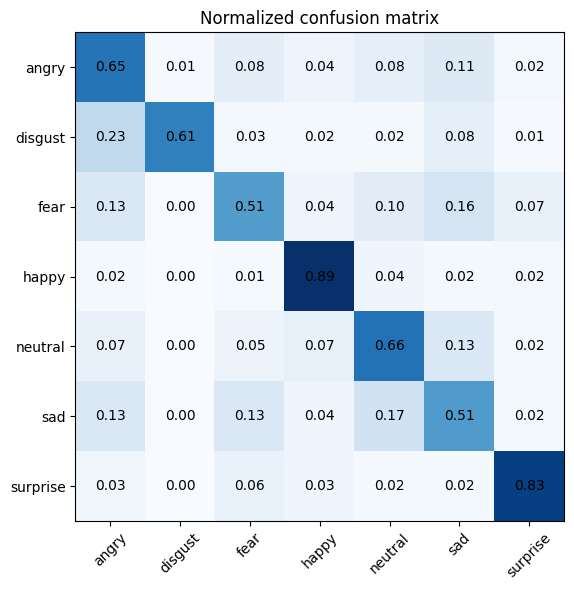

In [6]:
import torch, torch.nn as nn, numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

IMG, BS, EPOCHS, LR = 96, 64, 25, 3e-4
dev = "cuda" if torch.cuda.is_available() else "cpu"

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize(IMG),
    transforms.RandomHorizontalFlip(), transforms.RandomRotation(10),
    transforms.RandomResizedCrop(IMG, scale=(0.8, 1.0)),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize(IMG),
    transforms.ToTensor(), norm])

def main():
    # 90/10 train/val split from train folder; test folder stays untouched until the end
    tr_full = datasets.ImageFolder(f"{DATA}/train", train_tf)
    va_full = datasets.ImageFolder(f"{DATA}/train", eval_tf)
    test_ds = datasets.ImageFolder(f"{DATA}/test", eval_tf)
    classes = tr_full.classes

    idx = np.random.RandomState(42).permutation(len(tr_full))
    cut = int(0.9 * len(idx))
    tr_idx, va_idx = idx[:cut], idx[cut:]
    tr_dl = DataLoader(Subset(tr_full, tr_idx), BS, shuffle=True, num_workers=2)
    va_dl = DataLoader(Subset(va_full, va_idx), BS, num_workers=2)
    te_dl = DataLoader(test_ds, BS, num_workers=2)

    # class weights (softened) so 'disgust' isn't ignored
    counts = np.bincount(np.array(tr_full.targets)[tr_idx], minlength=7)
    w = torch.tensor((counts.sum() / (7 * counts)) ** 0.5, dtype=torch.float).to(dev)

    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(512, 7)
    model.to(dev)

    loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

    def evaluate(dl):
        model.eval(); preds, labels = [], []
        with torch.no_grad():
            for x, y in dl:
                preds += model(x.to(dev)).argmax(1).cpu().tolist()
                labels += y.tolist()
        return np.array(labels), np.array(preds)

    best = 0
    for ep in range(EPOCHS):
        model.train(); total = 0
        for x, y in tr_dl:
            x, y = x.to(dev), y.to(dev)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward(); opt.step()
            total += loss.item()
        sched.step()
        yv, pv = evaluate(va_dl)
        acc = (yv == pv).mean()
        print(f"epoch {ep+1}/{EPOCHS}  loss {total/len(tr_dl):.3f}  val_acc {acc:.4f}")
        if acc > best:
            best = acc; torch.save(model.state_dict(), "best_model.pt")

    # final evaluation on the held-out test set
    model.load_state_dict(torch.load("best_model.pt"))
    yt, pt = evaluate(te_dl)
    print(f"\nTest accuracy: {(yt == pt).mean():.4f}\n")
    print(classification_report(yt, pt, target_names=classes, digits=3))  # recall = per-class recall

    cm = confusion_matrix(yt, pt, normalize="true")
    plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues")
    plt.xticks(range(7), classes, rotation=45); plt.yticks(range(7), classes)
    for i in range(7):
        for j in range(7):
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center")
    plt.title("Normalized confusion matrix"); plt.tight_layout()
    plt.savefig("confusion_matrix.png")
    plt.show()

main()

In [15]:
from google.colab import drive
drive.mount('/content/drive')
!cp best_model.pt confusion_matrix.png /content/drive/MyDrive/

Mounted at /content/drive


In [7]:
import time, torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, f1_score

EPOCHS, BS, LR = 50, 128, 2e-3
dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print("Device:", dev)

Device: cuda


In [8]:
norm = transforms.Normalize([0.5], [0.5])

train_tf = transforms.Compose([
    transforms.Grayscale(1), transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(15, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(), norm, transforms.RandomErasing(p=0.25)])

eval_tf = transforms.Compose([transforms.Grayscale(1), transforms.ToTensor(), norm])

In [9]:
tr_full = datasets.ImageFolder(f"{DATA}/train", train_tf)
va_full = datasets.ImageFolder(f"{DATA}/train", eval_tf)
test_ds = datasets.ImageFolder(f"{DATA}/test", eval_tf)
classes = tr_full.classes

idx = np.random.RandomState(42).permutation(len(tr_full)); cut = int(0.9 * len(idx))
tr_idx, va_idx = idx[:cut], idx[cut:]

tr_dl = DataLoader(Subset(tr_full, tr_idx), BS, shuffle=True, num_workers=2)
va_dl = DataLoader(Subset(va_full, va_idx), BS, num_workers=2)
te_dl = DataLoader(test_ds, BS, num_workers=2)

print(classes)
print("Train:", len(tr_idx), " Val:", len(va_idx), " Test:", len(test_ds))

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train: 25838  Val: 2871  Test: 7178


In [10]:
counts = np.bincount(np.array(tr_full.targets)[tr_idx], minlength=7)
w = torch.tensor((counts.sum() / (7 * counts)) ** 0.5, dtype=torch.float).to(dev)
print(dict(zip(classes, counts)))
print(dict(zip(classes, w.cpu().numpy().round(2))))

{'angry': np.int64(3611), 'disgust': np.int64(397), 'fear': np.int64(3668), 'happy': np.int64(6521), 'neutral': np.int64(4476), 'sad': np.int64(4343), 'surprise': np.int64(2822)}
{'angry': np.float32(1.01), 'disgust': np.float32(3.05), 'fear': np.float32(1.0), 'happy': np.float32(0.75), 'neutral': np.float32(0.91), 'sad': np.float32(0.92), 'surprise': np.float32(1.14)}


In [11]:
def block(i, o, p):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p))

model = nn.Sequential(
    block(1, 64, 0.1), block(64, 128, 0.2), block(128, 256, 0.3), block(256, 512, 0.3),
    nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(512, 7)).to(dev)

print("Params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))

Params (M): 4.69


In [12]:
loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(tr_dl))

In [13]:
def evaluate(dl):
    model.eval(); P, L = [], []
    with torch.no_grad():
        for x, y in dl:
            P += model(x.to(dev)).argmax(1).cpu().tolist(); L += y.tolist()
    return np.array(L), np.array(P)

In [14]:
hist = dict(train_loss=[], val_acc=[]); best, t0 = 0, time.time()

for ep in range(EPOCHS):
    model.train(); total = 0
    for x, y in tr_dl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step(); sched.step()
        total += loss.item()
    yv, pv = evaluate(va_dl); acc = (yv == pv).mean()
    hist["train_loss"].append(total / len(tr_dl)); hist["val_acc"].append(acc)
    if acc > best: best = acc; torch.save(model.state_dict(), "scratch_cnn.pt")
    print(f"epoch {ep+1}/{EPOCHS}  loss {hist['train_loss'][-1]:.3f}  val_acc {acc:.4f}  ({(time.time()-t0)/60:.1f} min)")

epoch 1/50  loss 2.042  val_acc 0.2487  (0.3 min)
epoch 2/50  loss 1.952  val_acc 0.3406  (0.7 min)
epoch 3/50  loss 1.822  val_acc 0.4201  (1.0 min)
epoch 4/50  loss 1.728  val_acc 0.4584  (1.3 min)
epoch 5/50  loss 1.652  val_acc 0.4723  (1.6 min)
epoch 6/50  loss 1.603  val_acc 0.4535  (1.9 min)
epoch 7/50  loss 1.577  val_acc 0.5409  (2.2 min)
epoch 8/50  loss 1.546  val_acc 0.5430  (2.5 min)
epoch 9/50  loss 1.536  val_acc 0.5441  (2.8 min)
epoch 10/50  loss 1.519  val_acc 0.5064  (3.1 min)
epoch 11/50  loss 1.507  val_acc 0.4855  (3.4 min)
epoch 12/50  loss 1.487  val_acc 0.5556  (3.8 min)
epoch 13/50  loss 1.474  val_acc 0.5677  (4.1 min)
epoch 14/50  loss 1.461  val_acc 0.5904  (4.4 min)
epoch 15/50  loss 1.440  val_acc 0.5730  (4.7 min)
epoch 16/50  loss 1.428  val_acc 0.6036  (5.0 min)
epoch 17/50  loss 1.412  val_acc 0.5632  (5.3 min)
epoch 18/50  loss 1.402  val_acc 0.6085  (5.6 min)
epoch 19/50  loss 1.389  val_acc 0.6078  (5.9 min)
epoch 20/50  loss 1.375  val_acc 0.6200 

In [16]:
model.load_state_dict(torch.load("scratch_cnn.pt"))
yt, pt = evaluate(te_dl)
print(f"Test accuracy: {(yt == pt).mean():.4f}   Macro-F1: {f1_score(yt, pt, average='macro'):.4f}\n")
print(classification_report(yt, pt, target_names=classes, digits=3))


Test accuracy: 0.6934   Macro-F1: 0.6719

              precision    recall  f1-score   support

       angry      0.602     0.656     0.627       958
     disgust      0.643     0.649     0.646       111
        fear      0.567     0.475     0.517      1024
       happy      0.889     0.880     0.885      1774
     neutral      0.618     0.727     0.668      1233
         sad      0.594     0.519     0.554      1247
    surprise      0.789     0.826     0.807       831

    accuracy                          0.693      7178
   macro avg      0.672     0.676     0.672      7178
weighted avg      0.692     0.693     0.690      7178



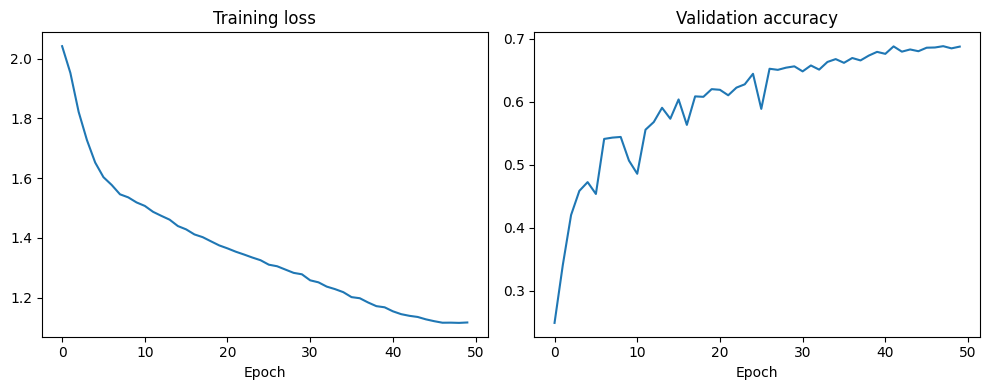

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(hist["train_loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("Epoch")
ax[1].plot(hist["val_acc"]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.savefig("scratch_curves.png", dpi=200); plt.show()

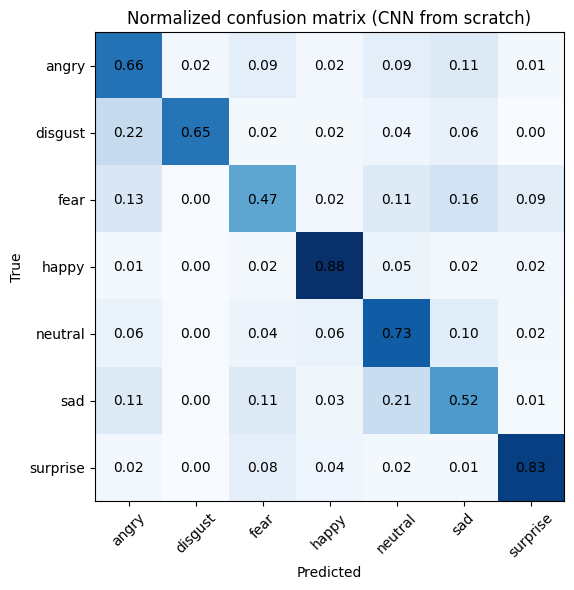

In [18]:
cm = confusion_matrix(yt, pt, normalize="true")
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(7), classes, rotation=45); plt.yticks(range(7), classes)
for i in range(7):
    for j in range(7): plt.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Normalized confusion matrix (CNN from scratch)")
plt.tight_layout(); plt.savefig("scratch_confusion.png", dpi=200); plt.show()

In [19]:
from google.colab import drive
drive.mount('/content/drive')
!cp scratch_cnn.pt scratch_curves.png scratch_confusion.png /content/drive/MyDrive/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
